# Part 0 — EDA, metric, validation and input pipeline

Hypotheses for this block (H0.1–H0.5) were committed in `HYPOTHESES.md` before this notebook was run.
Everything heavy lives in `src/soilgs`; this notebook only calls it and shows the evidence.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from soilgs import paths
from soilgs.data import load_labels, load_photos, load_photo, crop_tray, resample
from soilgs.metric import (COLS, SIEVES, WEIGHTS, emd, emd_per_sample, emd_trapezoid_per_sample,
                           emd_per_interval, shift_curve, d_percentile, d_errors)
from soilgs.folds import make_folds, assign_sites
from soilgs.features import pixel_centroid
from soilgs.tiles import TARGET_PPM, load_cached, tile_grid
from soilgs.baselines import tile_feature_table, mean_curve_oof, ridge_tile_oof, ridge_tile_test
from soilgs.experiment import save_experiment, fold_scores, compute_log, mean_std
from soilgs.submission import write_submission

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
labels, photos = load_labels(), load_photos()
folds = pd.read_csv(paths.FOLDS_CSV)
Y = labels[COLS].to_numpy(float)
print(f"{labels.shape[0]} labelled samples, {len(photos.query('split==\"train\"'))} train photos, "
      f"{photos.query('split==\"test\"').sample_id.nunique()} test samples, {len(photos.query('split==\"test\"'))} test photos")

24 labelled samples, 127 train photos, 10 test samples, 35 test photos


## 1. EDA
### Samples, photos, devices, scale

In [2]:
dev = photos.groupby(["split", "camera"]).agg(photos=("photo_id", "size"), samples=("sample_id", "nunique"),
                                              native_ppm=("native_ppm", "first"), effective_ppm=("ppm", "mean"),
                                              long_side_px=("width", "max"))
dev["field_of_view_mm"] = (photos.groupby(["split", "camera"]).apply(lambda g: (g[["width", "height"]].max(axis=1) / g.ppm).mean())).round(0)
display(dev.round(2))
per_sample = photos.groupby(["split", "sample_id"]).agg(photos=("photo_id", "size"), devices=("camera", "nunique"))
display(per_sample.groupby("split").agg(["min", "median", "max"]))

photos  samples  native_ppm  effective_ppm  long_side_px  field_of_view_mm
split camera                                                                                             
test  iPhone 14                    14        3       13.94          13.94          4032             289.0
      iPhone 16                    21        7       19.52          19.52          5712             293.0
train Motorola Edge                69       22       11.49           4.60          1600             348.0
      Motorola Edge 60 Fusion       3        1       12.46          12.46          4096             329.0
      Samsung A52                  55       22       26.33           4.55          1599             351.0

photos            devices           
         min median max     min median max
split                                     
test       3    3.0   5       1    1.0   1
train      3    5.0   8       1    2.0   2

**Takeaways.**
* 24 labelled samples, not 127: photos of one sample are repeated views of the same soil.
* The organisers downscaled the Motorola Edge and Samsung training photos, so they are **≈ 4.6 px/mm**,
  while the native px/mm in `ppm_updated.csv` is 11.5–26.3. Test photos are native: **14–19.5 px/mm**.
  Test images are therefore 3–4× sharper than anything the models are trained on. Everything below is
  resampled to a common 4.5 px/mm (the finest scale every photo has).
* Train and test use **disjoint devices** (Motorola/Samsung vs iPhone): device is confounded with split,
  which is one more reason to make the input depend on millimetres, not pixels.

### Curve shapes: fine vs coarse soils

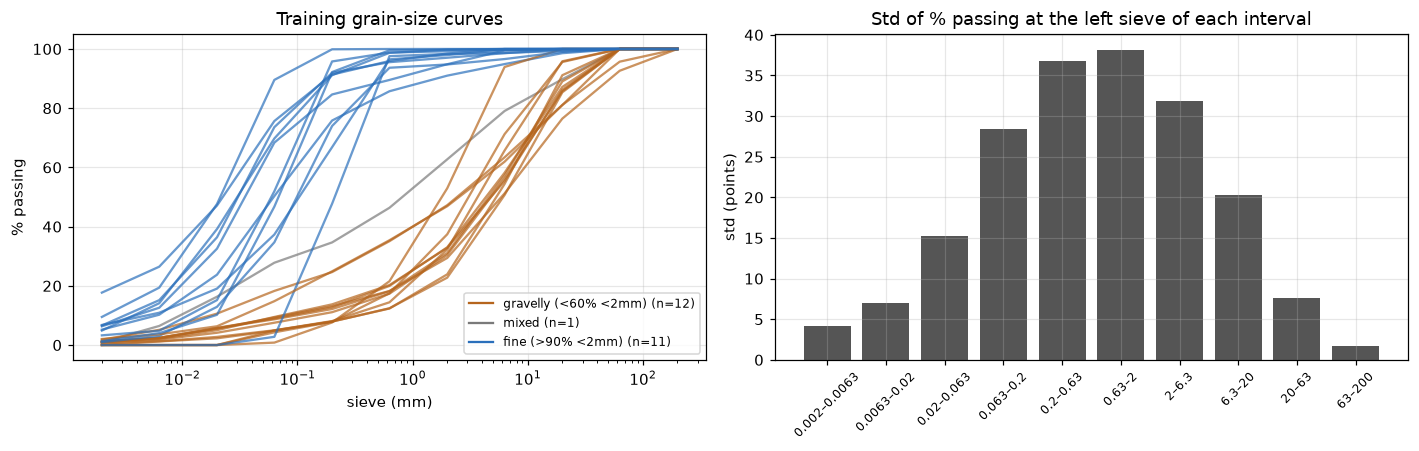

PCA variance explained by first 3 components: [0.914 0.062 0.014]


sample_id,F827,H405,H549,H668,H126,H493,G190,H666,H617,H030,...,H637,H181,H183,H371,H372,H366,H367,H615,H374,H368
pct_lt_0.063mm,89.56,75.66,69.76,73.59,68.36,51.95,50.31,46.75,34.7,37.32,...,14.82,4.3,4.95,8.94,8.69,9.48,7.54,4.84,9.3,4.98
pct_lt_2mm,100.0,98.45,99.75,97.04,94.85,99.21,90.99,99.79,94.77,97.95,...,46.89,37.41,32.28,33.01,31.06,32.82,30.41,23.88,29.42,22.76
D50_mm,0.02,0.02,0.03,0.03,0.03,0.06,0.06,0.07,0.1,0.1,...,2.54,3.07,3.67,4.34,4.59,4.79,4.79,5.34,5.91,6.13
D90_mm,0.07,0.18,0.19,0.18,0.7,0.17,1.61,0.19,0.51,0.49,...,34.37,15.33,15.99,25.76,22.07,27.43,28.15,19.3,52.23,28.76
group,fine (>90% <2mm),fine (>90% <2mm),fine (>90% <2mm),fine (>90% <2mm),fine (>90% <2mm),fine (>90% <2mm),fine (>90% <2mm),fine (>90% <2mm),fine (>90% <2mm),fine (>90% <2mm),...,gravelly (<60% <2mm),gravelly (<60% <2mm),gravelly (<60% <2mm),gravelly (<60% <2mm),gravelly (<60% <2mm),gravelly (<60% <2mm),gravelly (<60% <2mm),gravelly (<60% <2mm),gravelly (<60% <2mm),gravelly (<60% <2mm)


In [3]:
lab = labels.set_index("sample_id")
lab["pct_lt_2mm"] = lab["2"]
lab["pct_lt_0.063mm"] = lab["0.063"]
lab["D50_mm"] = [d_percentile(c, 50) for c in Y]
lab["D90_mm"] = [d_percentile(c, 90) for c in Y]
lab["group"] = pd.cut(lab.pct_lt_2mm, [-1, 60, 90, 101], labels=["gravelly (<60% <2mm)", "mixed", "fine (>90% <2mm)"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
colors = {"gravelly (<60% <2mm)": "#b5651d", "mixed": "#7a7a7a", "fine (>90% <2mm)": "#2a6fbb"}
for sid, row in lab.iterrows():
    ax[0].plot(SIEVES, row[COLS].astype(float), color=colors[row.group], alpha=.7)
for g, c in colors.items():
    ax[0].plot([], [], color=c, label=f"{g} (n={(lab.group == g).sum()})")
ax[0].set(xscale="log", xlabel="sieve (mm)", ylabel="% passing", title="Training grain-size curves")
ax[0].legend(fontsize=8)
ax[1].bar(range(10), labels[COLS].std().to_numpy()[:-1], color="#555")
ax[1].set_xticks(range(10), [f"{a}–{b}" for a, b in zip(COLS[:-1], COLS[1:])], rotation=45, fontsize=8)
ax[1].set(title="Std of % passing at the left sieve of each interval", ylabel="std (points)")
plt.tight_layout(); plt.show()

s = np.linalg.svd(Y - Y.mean(0), compute_uv=False)
print("PCA variance explained by first 3 components:", (s**2 / (s**2).sum())[:3].round(3))
display(lab[["pct_lt_0.063mm", "pct_lt_2mm", "D50_mm", "D90_mm", "group"]].sort_values("D50_mm").round(2).T)

**Takeaways.** Most samples are fine (silty/sandy) soils; only a handful are gravelly. The curves are
almost one-dimensional (one PC explains ~91 %), so the task is mostly "how coarse is it". Variance is
concentrated at 0.02–2 mm, exactly the sizes a 4.6 px/mm photo resolves worst (one pixel ≈ 0.22 mm).

## 2. Metric
Competition metric: **EMD** = Σᵢ |F_true(dᵢ) − F_pred(dᵢ)| · (log₁₀dᵢ₊₁ − log₁₀dᵢ) over the 10 intervals
(left-point rule). That is the area between the two cumulative curves on a log-diameter axis.
Interval weights:

In [4]:
print(dict(zip([f"{a}-{b}" for a, b in zip(COLS[:-1], COLS[1:])], WEIGHTS.round(3))))
uniform = np.tile(np.cumsum([100 / 11] * 11), (len(Y), 1))
loo_mean = np.array([np.delete(Y, i, 0).mean(0) for i in range(len(Y))])
print(f"uniform baseline EMD = {emd(Y, uniform):.1f}   LOO mean-curve EMD = {emd(Y, loo_mean):.1f}  "
      "(public notebooks report 102 / 90 -> implementation matches)")
r = pd.Series(emd_per_sample(Y, loo_mean)).corr(pd.Series(emd_trapezoid_per_sample(Y, loo_mean)), method="spearman")
print(f"left-point vs trapezoid rule (one public notebook used the latter): mean {emd(Y, loo_mean):.1f} vs "
      f"{emd_trapezoid_per_sample(Y, loo_mean).mean():.1f}, Spearman over samples {r:.3f}")

{'0.002-0.0063': np.float64(0.498), '0.0063-0.02': np.float64(0.502), '0.02-0.063': np.float64(0.498), '0.063-0.2': np.float64(0.502), '0.2-0.63': np.float64(0.498), '0.63-2': np.float64(0.502), '2-6.3': np.float64(0.498), '6.3-20': np.float64(0.502), '20-63': np.float64(0.498), '63-200': np.float64(0.502)}
uniform baseline EMD = 102.0   LOO mean-curve EMD = 89.9  (public notebooks report 102 / 90 -> implementation matches)
left-point vs trapezoid rule (one public notebook used the latter): mean 89.9 vs 89.1, Spearman over samples 0.999


### H0.2 — Where does the error mass live?

In [5]:
contrib = pd.Series(emd_per_interval(Y, loo_mean).mean(0), index=[f"{a}–{b}" for a, b in zip(COLS[:-1], COLS[1:])])
share = contrib / contrib.sum()
display((share * 100).round(1).to_frame("% of mean-curve EMD").T)
print(f"0.02–2 mm intervals: {share.iloc[2:6].sum():.0%} of the EMD;  ≥ 20 mm intervals: {share.iloc[8:].sum():.1%}")

,0.002–0.0063,0.0063–0.02,0.02–0.063,0.063–0.2,0.2–0.63,0.63–2,2–6.3,6.3–20,20–63,63–200
% of mean-curve EMD,1.7,3.2,7.1,14.3,19.7,21.2,17.3,11.1,3.9,0.5


0.02–2 mm intervals: 62% of the EMD;  ≥ 20 mm intervals: 4.4%


### H0.1 — What does a scale error cost?
A wrong px/mm by factor *k* makes every grain look *k* times bigger: F'(d) = F(d/k).

,1.10,1.25,1.50,2.00,3.00,4.00
mean,4.1,9.6,17.4,29.8,47.2,59.2
std,0.1,0.2,0.3,0.5,0.8,1.4
min,3.8,9.0,16.3,27.8,44.1,54.1
max,4.1,9.7,17.6,30.1,47.8,60.2


theory 100·log10(k): [np.float64(4.1), np.float64(9.7), np.float64(17.6), np.float64(30.1), np.float64(47.7), np.float64(60.2)];  k = 0.5 (grains read 2x smaller): 29.2 ± 1.2


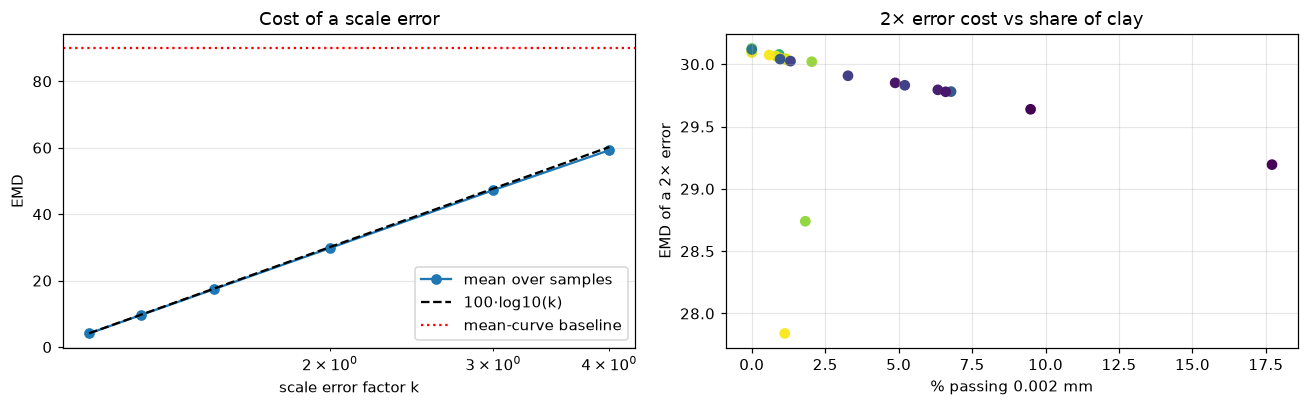

corr(2x cost, % < 0.002 mm) = -0.28 ; corr(2x cost, log D60/D10) = -0.39


In [6]:
factors = [1.1, 1.25, 1.5, 2, 3, 4]
cost = pd.DataFrame({k: emd_per_sample(Y, np.array([shift_curve(y, k) for y in Y])) for k in factors}, index=labels.sample_id)
cost_down = emd_per_sample(Y, np.array([shift_curve(y, 0.5) for y in Y]))
display(cost.agg(["mean", "std", "min", "max"]).round(1))
print(f"theory 100·log10(k): {[round(100 * np.log10(k), 1) for k in factors]};  k = 0.5 (grains read 2x smaller): "
      f"{cost_down.mean():.1f} ± {cost_down.std():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(factors, cost.mean(), "o-", label="mean over samples")
ax[0].plot(factors, 100 * np.log10(factors), "k--", label="100·log10(k)")
ax[0].axhline(emd(Y, loo_mean), color="r", ls=":", label="mean-curve baseline")
ax[0].set(xscale="log", xlabel="scale error factor k", ylabel="EMD", title="Cost of a scale error"); ax[0].legend()
ax[1].scatter(lab.loc[cost.index, "0.002"], cost[2], c=np.log10(lab.loc[cost.index, "D50_mm"]), cmap="viridis")
ax[1].set(xlabel="% passing 0.002 mm", ylabel="EMD of a 2× error", title="2× error cost vs share of clay")
plt.tight_layout(); plt.show()
print("corr(2x cost, % < 0.002 mm) =", round(np.corrcoef(lab.loc[cost.index, "0.002"], cost[2])[0, 1], 2),
      "; corr(2x cost, log D60/D10) =",
      round(np.corrcoef(np.log10([d_percentile(y, 60) / d_percentile(y, 10) for y in Y]), cost[2])[0, 1], 2))

### Complementary and alternative metric
* **Complementary: D10 / D50 / D60 error in log₁₀(mm).** Engineers use these numbers directly (e.g. the
  uniformity coefficient Cu = D60/D10). An EMD of 30 can mean "the whole curve is one octave off" or
  "the fines are 30 points wrong"; D-errors tell the two apart. Reported for every model alongside EMD.
* **Alternative target metric: EMD on the *continuous* log-d axis with soil-class-weighted bands**, or
  simply the mean absolute error of the four ISO 14688 fractions (clay < 0.002, silt 0.002–0.063,
  sand 0.063–2, gravel > 2 mm). Justification: the left-point rule never looks at the 63–200 mm interval
  (the error at 200 mm is always 0) and gives the clay share as much weight as a whole sand decade;
  the fraction-MAE measures what a geotechnical classification actually uses and is insensitive to how
  the sieves are spaced.

In [7]:
d_err = pd.DataFrame(d_errors(Y, loo_mean), columns=["D10", "D50", "D60"], index=labels.sample_id)
print("mean-curve baseline, |Δlog10 D| (1.0 = one decade off):"); display(d_err.mean().round(3).to_frame().T)

mean-curve baseline, |Δlog10 D| (1.0 = one decade off):


,D10,D50,D60
0,0.755,0.992,1.0


## 3. Validation: site-grouped folds
Photos of one sample never span train/validation; predictions are aggregated to one curve per sample
before scoring. Folds also hold out whole **sites** (consecutive ids of one letter, e.g. H366–H374),
because test samples come from sites absent from training. `data/folds.csv` is created once (seed 42,
StratifiedGroupKFold stratified on D50 tercile) and used by **every** experiment.

In [8]:
display(folds.assign(D50=lambda d: d.sample_id.map(lab.D50_mm).round(3)).groupby("fold")
        .agg(samples=("sample_id", list), sites=("site", "nunique"), median_D50=("D50", "median")))

,samples,sites,median_D50
fold,,,
0,"[F827, H030, H037, H038, H126]",3,0.1030
1,"[H516, H666, H668]",2,0.0680
2,"[H366, H367, H368, H371, H372, H374, H493]",2,4.7910
3,"[G190, H405, H615, H616, H617]",3,0.0990
4,"[H181, H183, H549, H637]",3,2.8005


### Baselines on the shared folds (logged to `experiments/`)
Texture baseline: per-tile mm-indexed difference-of-Gaussian energies + Lab colour moments (23 features,
`soilgs.features`), ridge (α = 10, fixed a priori, not tuned) on √mass targets, tile → photo → sample
averaging.

In [9]:
with compute_log() as c:
    oof_mean = mean_curve_oof(labels, folds)
m = save_experiment("p0_mean_curve", {"model": "fold mean curve"}, oof_mean, labels, folds, c, part="0")
print(f"mean curve: CV {m['cv_mean']:.2f} ± {m['cv_std']:.2f}")

tiles = {t: tile_feature_table(photos, t) for t in (25, 50, 100)}
for t, df in tiles.items():
    print(f"{t:>3} mm tiles: {len(df)} tiles, {df.groupby('photo_id').size().median():.0f} per photo")

mean curve: CV 93.41 ± 9.58
 25 mm tiles: 15365 tiles, 88 per photo
 50 mm tiles: 4255 tiles, 24 per photo
100 mm tiles: 1422 tiles, 8 per photo


### H0.4 — Tile size in millimetres

In [10]:
res = {}
for t in (25, 50, 100):
    with compute_log() as c:
        oof = ridge_tile_oof(tiles[t], labels, folds, alpha=10)
    cfg = {"model": "ridge", "alpha": 10, "target": "sqrt_mass", "features": "texture (23)", "tile_mm": t, "ppm": TARGET_PPM}
    m = save_experiment(f"p0_texture_ridge_{t}mm", cfg, oof, labels, folds, c, part="0")
    per_sample, _ = fold_scores(oof, labels, folds)
    res[t] = {"CV mean ± std (5 site folds)": f"{m['cv_mean']:.2f} ± {m['cv_std']:.2f}",
              "gravelly samples": per_sample[lab.loc[per_sample.index, "group"] == "gravelly (<60% <2mm)"].mean().round(2),
              "other samples": per_sample[lab.loc[per_sample.index, "group"] != "gravelly (<60% <2mm)"].mean().round(2)}
    if t == 50:
        oof_texture50 = oof
display(pd.DataFrame(res).T)

alpha_sweep = {a: emd(labels.set_index("sample_id").loc[o.index, COLS].to_numpy(float), o.to_numpy())
               for a in (1, 10, 100, 1000) for o in [ridge_tile_oof(tiles[50], labels, folds, alpha=a)]}
print("alpha sweep at 50 mm (reported, not used for selection):", {a: round(v, 2) for a, v in alpha_sweep.items()})

,CV mean ± std (5 site folds),gravelly samples,other samples
25,38.55 ± 13.28,33.66,41.84
50,38.17 ± 14.62,31.35,42.47
100,38.15 ± 14.86,30.7,42.57


alpha sweep at 50 mm (reported, not used for selection): {1: 37.27, 10: 36.91, 100: 36.58, 1000: 38.66}


Tile size choice for the deep models: at 4.5 px/mm, **50 mm = 225 px**, the native input of ImageNet
CNNs/ViTs at 224 px, so no resizing (which would change mm/px) is ever needed; 100 mm = 450 px is the
"large context" alternative tested later as an input-resolution ablation. Training-set D90 is ≤ 20 mm for
all but the coarsest samples, so a 50 mm tile holds several of the grains that carry the mass.

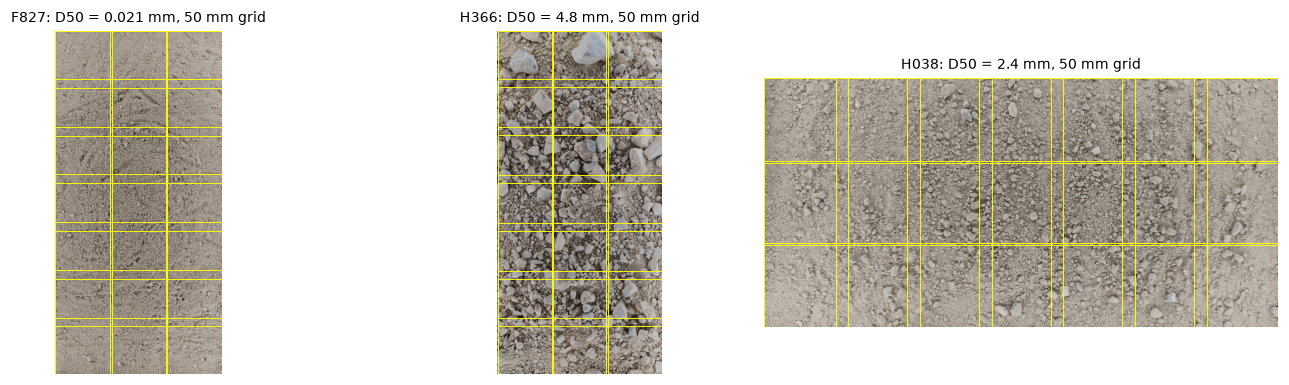

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, sid in zip(ax, ["F827", "H366", "H038"]):
    row = photos[(photos.sample_id == sid) & (photos.split == "train")].iloc[0]
    img = load_cached(row.photo_id)
    a.imshow(img)
    for y, x, t in tile_grid(*img.shape[:2], 50):
        a.add_patch(plt.Rectangle((x, y), t, t, fill=False, ec="yellow", lw=.6))
    a.set_title(f"{sid}: D50 = {lab.loc[sid, 'D50_mm']:.2g} mm, 50 mm grid", fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

### H0.3 — Site-grouped vs sample-grouped folds

In [12]:
rows = []
for group in ("site", "sample"):
    for seed in range(5):
        f = make_folds(labels, COLS, group=group, seed=seed)
        _, per_fold = fold_scores(ridge_tile_oof(tiles[50], labels, f, alpha=10), labels, f)
        rows.append({"grouping": group, "seed": seed, "cv_mean": per_fold.mean(), "fold_std": per_fold.std(ddof=0)})
grp = pd.DataFrame(rows)
display(grp.groupby("grouping")[["cv_mean", "fold_std"]].agg(["mean", "std"]).round(2))

cv_mean       fold_std      
            mean   std     mean   std
grouping                             
sample     36.47  1.06     9.32  5.40
site       40.97  1.55    13.11  2.05

### H0.5 — The train/test resolution gap
A pixel-indexed texture scale (DoG energy centroid in log₂ pixels, `features.pixel_centroid`) on each
tray crop, at native resolution vs after resampling to 4.5 px/mm.

test samples inside the training range: {'native': 8, 'resampled': 7} of 10


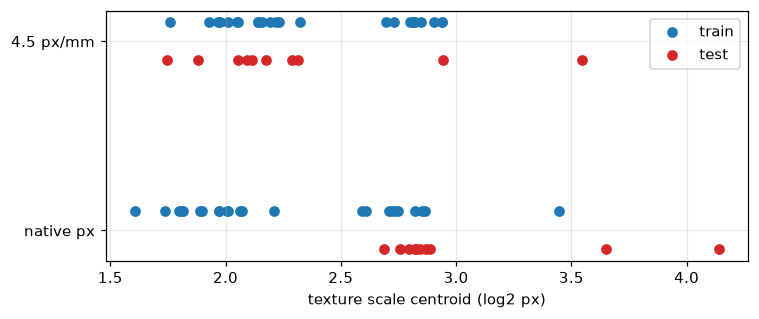

sample_id,HPC_Airbus BS10-4bis7,HPC_Airbus BS12-5bis8,HPC_Airbus BS6-3,HPC_Audorfring,HPC_Kleinkummerfeld 18-3,HPC_Kleinkummerfeld 2-2,HPC_Kleinkummerfeld 2-3,HPC_Kleinkummerfeld 9-4,HPC_Muenster_BS6_9_0-10m,HPC_Testfeld Lidl WHV
native,2.76,2.84,2.82,2.89,2.83,2.69,2.80,2.87,4.14,3.65
resampled,2.09,2.29,2.12,2.32,2.06,1.75,1.88,2.18,3.55,2.94


In [13]:
rows = []
for r in photos.itertuples():
    crop, _ = crop_tray(load_photo(r.path))
    rows.append({"split": r.split, "sample_id": r.sample_id, "native": pixel_centroid(crop),
                 "resampled": pixel_centroid(load_cached(r.photo_id))})
pc = pd.DataFrame(rows).groupby(["split", "sample_id"])[["native", "resampled"]].mean()
inside = {}
for col in ("native", "resampled"):
    lo, hi = pc.loc["train", col].min(), pc.loc["train", col].max()
    inside[col] = int(pc.loc["test", col].between(lo, hi).sum())
print("test samples inside the training range:", inside, "of", len(pc.loc["test"]))
fig, ax = plt.subplots(figsize=(7, 3))
for i, col in enumerate(("native", "resampled")):
    ax.scatter(pc.loc["train", col], np.full(24, i + .1), c="C0", label="train" if i == 0 else None)
    ax.scatter(pc.loc["test", col], np.full(len(pc.loc["test"]), i - .1), c="C3", label="test" if i == 0 else None)
ax.set_yticks([0, 1], ["native px", "4.5 px/mm"]); ax.set_xlabel("texture scale centroid (log2 px)"); ax.legend()
plt.tight_layout(); plt.show()
display(pc.loc["test"].round(2).T)

## 4. First submission (texture baseline, 50 mm tiles)
Fit on all 24 samples, predict test. Written to `submissions/`; it is submitted and its public/private LB
recorded in the results table. The model was chosen by CV only.

In [14]:
test_curves = ridge_tile_test(tiles[50], labels, alpha=10)
sub = write_submission(test_curves, paths.ROOT / "submissions" / "p0_texture_ridge_50mm.csv")
display(sub.round(1))

,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
0,HPC_Airbus BS6-3,0.4,2.3,6.4,32.7,57.8,68.1,77.2,89.1,96.5,99.5,100.0
1,HPC_Audorfring,0.3,1.2,2.9,10.8,21.2,32.7,48.9,73.1,92.1,99.6,100.0
2,HPC_Muenster_BS6_9_0-10m,0.8,1.3,2.9,9.8,23.1,38.3,50.4,71.3,91.5,99.7,100.0
3,HPC_Airbus BS10-4bis7,0.5,2.8,7.6,35.5,60.0,68.6,77.3,88.9,96.5,99.6,100.0
4,HPC_Airbus BS12-5bis8,0.4,2.5,6.6,31.2,53.0,62.8,72.9,86.6,95.9,99.6,100.0
5,HPC_Kleinkummerfeld 2-2,1.5,3.5,10.2,41.1,75.7,85.7,90.9,96.4,98.7,99.8,100.0
6,HPC_Kleinkummerfeld 2-3,0.6,1.5,5.5,36.1,71.0,78.6,85.9,94.5,98.3,99.8,100.0
7,HPC_Kleinkummerfeld 9-4,0.2,1.5,4.4,27.5,49.0,57.2,68.7,85.0,95.7,99.6,100.0
8,HPC_Kleinkummerfeld 18-3,0.3,1.7,4.9,27.2,50.7,61.5,72.6,87.2,95.9,99.5,100.0
9,HPC_Testfeld Lidl WHV,0.0,0.2,0.3,1.7,3.7,10.5,27.5,58.3,88.4,99.7,100.0
